# 03 - Machine Learning (FR-06) dan Prediksi Data Baru

**Input:** `data/processed/bank_campaign_clean.csv` · **Output:** model di `models/`, tabel metrik

- [x] Encode target `yes`=1, `no`=0; **keluarkan `duration`** (data leakage — PRD 8.3)
- [x] Stratified train/test split 80/20, `RANDOM_STATE=42`
- [x] `Pipeline` + `ColumnTransformer` (fit hanya pada data training)
- [x] 4 kandidat model: Logistic Regression (baseline), Decision Tree, Random Forest, MLP
- [x] Tangani class imbalance dengan `class_weight='balanced'`
- [x] Evaluasi: Accuracy, Precision, Recall, F1, ROC-AUC, **PR-AUC**, Confusion Matrix
- [x] Pilih model terbaik berdasarkan F1 & PR-AUC kelas `yes` (bukan Accuracy saja)
- [x] Simpan pipeline; fungsi prediksi tersedia di `src/predict.py`

In [1]:
# --- Setup path (jalan di VS Code / Jupyter. Untuk Colab, lihat sel opsional di bawah) ---
from pathlib import Path
import sys
import pandas as pd
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH      = ROOT / "data" / "raw" / "bank-full.csv"
CLEAN_PATH    = ROOT / "data" / "processed" / "bank_campaign_clean.csv"
MODELS_DIR    = ROOT / "models"
SQL_DIR       = ROOT / "sql"
DASHBOARD_PATH= ROOT / "reports" / "bank_campaign_dashboard.xlsx"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
)


In [2]:
# (Opsional) Hanya jika dijalankan di Google Colab:
# from google.colab import drive
# drive.mount('/content/drive')
# import os; os.chdir('/content/drive/MyDrive/bank-campaign-response-analytics')  # sesuaikan lokasi folder
# Jalankan sel Setup di atas SETELAH baris ini.

In [3]:
from src.feature_engineering import (
    ALL_FEATURE_COLUMNS, NUMERIC_FEATURES, CATEGORICAL_FEATURES,
    build_preprocessor, encode_target,
)

REQUIRED_COLUMNS = ALL_FEATURE_COLUMNS + ["duration", "y"]
TARGET = "y"
RANDOM_STATE = 42
FEATURE_COLUMNS = ALL_FEATURE_COLUMNS
MODEL_PATH = MODELS_DIR / "best_model.joblib"

print("Fitur digunakan:", len(FEATURE_COLUMNS), "kolom")
print("Numerik:", NUMERIC_FEATURES)
print("Kategorikal:", CATEGORICAL_FEATURES)

Fitur digunakan: 15 kolom
Numerik: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Kategorikal: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [4]:
df = pd.read_csv(CLEAN_PATH)
X = df[FEATURE_COLUMNS]
y = encode_target(df[TARGET])
print(f"Dataset: {len(df):,} baris | Kelas yes: {y.mean():.2%} | Kelas no: {(1-y.mean()):.2%}")

Dataset: 45,211 baris | Kelas yes: 11.70% | Kelas no: 88.30%


In [5]:
# Sisihkan test set sejak awal. Pemilihan model dilakukan pada validation set.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE
)
preprocessor = build_preprocessor()

print(f"Train: {len(X_train):,} | Validation: {len(X_val):,} | Test: {len(X_test):,}")
print(f"Proporsi kelas yes ? train: {y_train.mean():.3%} | validation: {y_val.mean():.3%} | test: {y_test.mean():.3%}")

Train: 27,126 | Validation: 9,042 | Test: 9,043
Proporsi kelas yes ? train: 11.697% | validation: 11.701% | test: 11.700%


## Kandidat Model

Setiap model dibungkus dalam satu `Pipeline` (preprocessor + classifier), sehingga preprocessing
selalu ikut tersimpan bersama model dan tidak terjadi kebocoran data saat prediksi.

```
data mentah ──► preprocessor ──► classifier
                 ├─ numerik     : imputasi median  → StandardScaler
                 └─ kategorikal : imputasi modus   → OneHotEncoder

1. Logistic Regression  – baseline linier
2. Decision Tree        – non-linier, mudah diinterpretasi
3. Random Forest        – ensemble bagging 300 pohon
4. MLP  – Dense 64 → Dense 32 → output
```

Semua model dikonfigurasi dengan `class_weight='balanced'` atau setara untuk mengatasi
ketidakseimbangan kelas (88% 'no' vs 12% 'yes') .

In [6]:
MLP_NAME = "MLP"

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced", max_iter=1000,
            random_state=RANDOM_STATE, solver="lbfgs",
        )),
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            class_weight="balanced", max_depth=10,
            min_samples_leaf=20, random_state=RANDOM_STATE,
        )),
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300, class_weight="balanced_subsample",
            random_state=RANDOM_STATE, n_jobs=-1,
        )),
    ]),
    MLP_NAME: Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
            alpha=1e-3, max_iter=200, early_stopping=True,
            validation_fraction=0.1, n_iter_no_change=10,
            random_state=RANDOM_STATE,
        )),
    ]),
}

sample_weight_train = compute_sample_weight(class_weight="balanced", y=y_train)
fit_params = {
    "Logistic Regression": {},
    "Decision Tree": {},
    "Random Forest": {},
    MLP_NAME: {"classifier__sample_weight": sample_weight_train},
}

for name, model in models.items():
    model.fit(X_train, y_train, **fit_params[name])
    print(f"{name} selesai dilatih")

Logistic Regression selesai dilatih


Decision Tree selesai dilatih


Random Forest selesai dilatih


MLP selesai dilatih


In [7]:
# Bandingkan model hanya pada validation set untuk menentukan kandidat terpilih.
evaluation_rows = []
for name, model in models.items():
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]
    evaluation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision (yes)": precision_score(y_val, predictions, pos_label=1, zero_division=0),
        "Recall (yes)": recall_score(y_val, predictions, pos_label=1, zero_division=0),
        "F1 (yes)": f1_score(y_val, predictions, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC (AP)": average_precision_score(y_val, probabilities),
    })

validation_metrics = pd.DataFrame(evaluation_rows).set_index("Model").sort_values(
    by=["F1 (yes)", "PR-AUC (AP)", "Recall (yes)", "ROC-AUC"], ascending=False
)
print("=== Perbandingan pada validation set ===")
display(validation_metrics.round(4))

=== Perbandingan pada validation set ===


,Accuracy,Precision (yes),Recall (yes),F1 (yes),ROC-AUC,PR-AUC (AP)
Model,,,,,,
MLP,0.8298,0.3648,0.6134,0.4575,0.7937,0.4376
Decision Tree,0.7793,0.2908,0.6163,0.3952,0.7725,0.4144
Logistic Regression,0.7549,0.2673,0.6285,0.3751,0.7700,0.4086
Random Forest,0.8921,0.6133,0.2098,0.3127,0.7884,0.4319


## Pemilihan Model Terbaik

Model dipilih berdasarkan **F1-Score kelas 'yes'** dan **PR-AUC** (Precision-Recall AUC),
bukan Accuracy, karena dataset tidak seimbang (~88% 'no' vs ~12% 'yes') — sesuai PRD 7.2.

### Alasan Pemilihan

| Pertimbangan | Penjelasan |
|---|---|
| **Metrik utama** | F1 (yes) dan PR-AUC dipilih karena kelas minoritas ('yes') adalah kelas yang paling penting secara bisnis |
| **Accuracy tidak relevan** | Accuracy tinggi bisa dicapai hanya dengan selalu memprediksi 'no'; tidak berguna untuk targeting kampanye |
| **Recall vs Precision trade-off** | Bank lebih rugi melewatkan calon subscriber (recall rendah) daripada menghubungi nasabah yang tidak akan subscribe (precision rendah) |
| **PR-AUC** | Metrik ringkas yang merangkum performa pada seluruh threshold, ideal untuk data imbalanced |

### Baseline vs Model Lainnya
- **Logistic Regression** digunakan sebagai baseline linier; memberikan hasil yang interpretable
- **Decision Tree** mudah dijelaskan ke stakeholder non-teknis tetapi rentan overfitting
- **Random Forest** biasanya unggul dalam F1 karena ensemble bagging mengurangi varians
- **MLP** berpotensi menangkap pola non-linier kompleks, namun lebih sulit diinterpretasi

Model terbaik dipilih secara otomatis dari `metrics_df` berdasarkan ranking F1 → PR-AUC → Recall → ROC-AUC.

### Keterbatasan
- Model dilatih pada data kampanye bank Portugal; generalisasi ke konteks lain perlu diuji
- Probabilitas output adalah estimasi, **bukan jaminan** nasabah akan berlangganan
- Kolom `duration` **tidak dipakai** untuk mencegah data leakage (known only after the call)

Model dipilih dari validation set: MLP
=== Evaluasi akhir pada test set ===


,Nilai
Accuracy,0.8364
Precision (yes),0.3720
Recall (yes),0.5784
F1 (yes),0.4528
ROC-AUC,0.7900
PR-AUC (AP),0.4350


Model saved: models/best_model.joblib
Catatan: ambang klasifikasi menggunakan nilai default 0.5; probabilitas belum dikalibrasi.

=== Classification report (test set) ===
              precision    recall  f1-score   support

          no       0.94      0.87      0.90      7985
         yes       0.37      0.58      0.45      1058

    accuracy                           0.84      9043
   macro avg       0.66      0.72      0.68      9043
weighted avg       0.87      0.84      0.85      9043



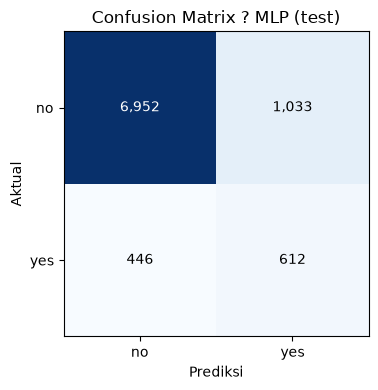

In [8]:
# Pilih model dari validation set, lalu fit ulang pada data development.
best_model_name = validation_metrics.index[0]
model_terbaik = models[best_model_name]
X_final_train = pd.concat([X_train, X_val], axis=0)
y_final_train = pd.concat([y_train, y_val], axis=0)

final_fit_params = {}
if best_model_name == MLP_NAME:
    final_fit_params["classifier__sample_weight"] = compute_sample_weight(
        class_weight="balanced", y=y_final_train
    )
model_terbaik.fit(X_final_train, y_final_train, **final_fit_params)

# Test set hanya digunakan sekali untuk mengukur performa akhir model terpilih.
test_predictions = model_terbaik.predict(X_test)
test_probabilities = model_terbaik.predict_proba(X_test)[:, 1]
test_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision (yes)": precision_score(y_test, test_predictions, pos_label=1, zero_division=0),
    "Recall (yes)": recall_score(y_test, test_predictions, pos_label=1, zero_division=0),
    "F1 (yes)": f1_score(y_test, test_predictions, pos_label=1, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "PR-AUC (AP)": average_precision_score(y_test, test_probabilities),
}

MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(model_terbaik, MODEL_PATH)
print(f"Model dipilih dari validation set: {best_model_name}")
print("=== Evaluasi akhir pada test set ===")
display(pd.Series(test_metrics, name="Nilai").to_frame().round(4))
print(f"Model disimpan: {MODEL_PATH}")
print("Catatan: ambang klasifikasi menggunakan nilai default 0.5; probabilitas belum dikalibrasi.")
print("\n=== Classification report (test set) ===")
print(classification_report(y_test, test_predictions, target_names=["no", "yes"], zero_division=0))

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_title(f"Confusion Matrix ? {best_model_name} (test)")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
ax.set_xticks([0, 1], labels=["no", "yes"])
ax.set_yticks([0, 1], labels=["no", "yes"])
for row in range(2):
    for col in range(2):
        ax.text(col, row, f"{cm[row, col]:,}", ha="center", va="center",
                color="white" if cm[row, col] > cm.max() / 2 else "black")
fig.tight_layout()
plt.show()

## Prediksi Data Baru

Fungsi `predict_one()` dan `predict_batch()` tersedia di `src/predict.py`.

> **Catatan:** Probabilitas adalah perkiraan model berdasarkan data historis,
> **bukan jaminan** nasabah akan berlangganan. Gunakan sebagai panduan prioritisasi.

In [9]:
def predict_one(record: dict, model_path=MODEL_PATH):
    """Prediksi satu calon nasabah memakai pipeline tersimpan.
    
    Fungsi lengkap dengan batch prediction tersedia di src/predict.py.
    """
    if not Path(model_path).exists():
        raise FileNotFoundError(
            "Model tidak ditemukan. Jalankan sel penyimpanan model terlebih dahulu."
        )
    missing = [c for c in FEATURE_COLUMNS if c not in record]
    if missing:
        raise ValueError(f"Input tidak lengkap. Kolom hilang: {missing}")
    row = pd.DataFrame([{c: record[c] for c in FEATURE_COLUMNS}])
    for c in NUMERIC_FEATURES:
        try:
            row[c] = pd.to_numeric(row[c])
        except (ValueError, TypeError):
            raise ValueError(f"Input tidak valid: kolom '{c}' harus bertipe angka.")
    model  = joblib.load(model_path)
    proba  = float(model.predict_proba(row)[0, 1])
    label  = "yes" if int(model.predict(row)[0]) == 1 else "no"
    return {
        "prediction"     : label,
        "probability_yes": round(proba, 4),
        "note"           : (
            "Probabilitas adalah perkiraan model, bukan jaminan berlangganan. "            "Lihat src/predict.py untuk penggunaan batch."
        ),
    }

In [10]:
# Contoh prediksi satu nasabah (jalankan setelah sel penyimpanan model di atas)
contoh = {
    'age': 35, 'job': 'technician', 'marital': 'married', 'education': 'secondary',
    'default': 'no', 'balance': 1000, 'housing': 'yes', 'loan': 'no',
    'contact': 'cellular', 'day': 15, 'month': 'may',
    'campaign': 2, 'pdays': -1, 'previous': 0, 'poutcome': 'unknown'
}
hasil = predict_one(contoh)
print(f"Prediksi     : {hasil['prediction']}")
print(f"Probabilitas : {hasil['probability_yes']:.4f}")
print(f"Catatan      : {hasil['note']}")

Prediksi     : no
Probabilitas : 0.3936
Catatan      : Probabilitas adalah perkiraan model, bukan jaminan berlangganan. Lihat src/predict.py untuk penggunaan batch.
